**Bitácora · Day 1 NMF (letrozole)**

- **v1** `Day1_nmf_v1`  
  Group tags, visit events kept. *Files:* `nmf_k8_letrozole.npz`
- **v2** `Day1_nmf_v2`  
  Visit events removed before tagging. *Files:* `nmf_k8_letrozole_v2.npz`
- **v3** `Day1_nmf_v3` (2026-10-07) ← **this notebook**  
  Concept-level tokens; a concept counts in every codeset it matches. *Files:* `nmf_k8_letrozole_v3.npz`

# Day 1 · v3 (concept-level tokens) · The letrozole cohort, and why a bag of codes fails

**Today's goal, in one sentence:** show a real example of two patients who look *completely identical* to a computer but are medically opposite cases — and use that to explain why the simplest way of describing a patient (a checklist of "does the patient have code X: yes/no") throws away exactly the information a good model would need.

**The problem.** Letrozole is prescribed for two unrelated reasons: as first-line ovulation induction for infertility, or as adjuvant aromatase-inhibitor therapy after breast cancer treatment. A bare drug-exposure code doesn't say which — the same molecule, the same claim shape, opposite clinical meaning.

*In plain terms: if all you know is "this patient was given letrozole," you cannot tell whether they're trying to get pregnant or recovering from cancer treatment. The drug code alone is silent on the reason it was prescribed.*

**The cohort**, from `sql/letrozole_cohort.sql`: every patient with a letrozole drug exposure (the RxNorm ingredient `letrozole` plus its standard descendant products — branded tablets, dose forms — resolved through `concept_ancestor`). This is the drug side of the ambiguity: anchoring on the exposure itself, rather than on a breast-cancer diagnosis, captures both indications by construction instead of biasing the sample toward oncology.

**The working hypothesis** (to test, not assume): anchoring on the drug rather than the cancer diagnosis should surface a much larger fertility-treatment population than a breast-cancer-anchored cohort would, since oncology-indication letrozole use is a small fraction of all letrozole prescriptions. `weak_labels()` and the NMF components below test this directly.

**Today's sub-goals:** get the OMOP extract for this cohort loaded as one event stream, understand the four preprocessing decisions baked into it, and see the exact failure that motivates the rest of the week.

### Summary

Every unsupervised method is a distance function plus a search procedure. Changing the
representation moves the answer more than changing the algorithm does, so the leverage is
upstream. Today is the upstream.

*In plain terms: "representation" just means how we turn a patient's messy history of visits, diagnoses, and prescriptions into rows and columns a computer can compare. Get that step wrong, and no amount of clever math afterward can fix it — the information is simply gone by the time the algorithm sees it. That's why today is entirely about that first step, before any modeling happens.*

### Three things that all get called "pattern"

*People use the word "pattern" loosely, for at least three different things. This table pins those down, so when someone says "we found a pattern," you know which of the three they mean and how much to trust it.*

| Term | What it is | Built on | Auditable? |
|---|---|---|---|
| **Cluster** | a group of similar patients | Day 2 | partly |
| **Motif** | a recurring *ordered* subsequence | Day 3 | yes |
| **Embedding** | a direction in a learned space | Day 4 | no |

Motifs are the current best deliverable for this project

### Technique chosen per subtopic

*For each question below, several statistical tools could answer it. This is the one this course uses, and why — the alternatives are listed too, in case a stakeholder asks "why not X."*

| Subtopic | We use | Mentioned only |
|---|---|---|
| Similarity | **cosine** on binary codes | Jaccard, Dice, Gower, Mahalanobis |
| Linear reduction | **truncated SVD** | PCA (same thing, dense), ICA, factor analysis |
| Parts-based | **NMF** | archetypal analysis, sparse PCA |
| Non-linear view | **t-SNE** (ships with sklearn) | UMAP — better, `pip install umap-learn` |

> **Day 1 v3 = Day 1 v2 with concept-level tokens; v2 is untouched.**
> `eo.tag_events(..., token_level="concept")` gives every event its own token (`<name20>__<class>__<concept_id>`), curated ones
> included, so the bag of codes, prevalence floor and NMF see each concept separately. The curated group (`letrozole`, `ekg`, ...) is
> kept only in `events.group`. Cells that select a group by name (anchor drop, probe labels, the two-patient demo, Table 1, the
> watch-list loadings) read `events.group`. The loadings table sums a group's concept-token loadings. The NMF is refit and cached
> as `nmf_k8_letrozole_v3.npz`, so component numbers and top codes can differ from v2: read the top tokens again before naming components.

## 0 · Getting the data

**Goal:** pull every letrozole-exposed patient's medical history out of the data warehouse and save it to disk as plain files, so the rest of the notebook runs offline and reproducibly, without hitting Snowflake every time.

`ethos_omop.extract_cohort()` pulls the letrozole-exposure cohort: any patient with a letrozole drug exposure, defined in `sql/letrozole_cohort.sql`. It dumps the same shape `extract_omop()` does — `master_*` as the source of truth, `ethos_dip` excluded on both `concept_id` and `source_concept_id` for every domain table, standard-named symlinks for `meds_etl_omop`, plus:

* **`concept.csv` slimmed** to the concept_ids the cohort actually references, instead of the full multi-million-row table.
* **`concept_ancestor` dumped too**, restricted to rows touching the cohort — needed for ontology rollup (drug products to ingredients, unspecified diagnoses to their parents).

*In plain terms: this is a one-time data export, like running a big report and saving the results as spreadsheets (CSV files) in a folder. Every cell below reads from that folder, not from Snowflake directly.*

```python
import ethos_omop as eo
eo.extract_cohort("../../sql/letrozole_cohort.sql")   # -> ../../inputs/letrozole_cohort/
```

The next cell runs this once and skips it on every re-run once `../../inputs/letrozole_cohort/` exists.

**No Snowflake access, or want to see the notebook run against data whose right answer you already know?** Use the synthetic demo extract instead:

```bash
python make_demo_extract.py 2000
```

The demo extract has the **same schema** — integer `concept_id`s resolved through `concept.csv`, `master_*` table names, the symlinks — plus a `truth.csv` giving each patient's planted trajectory archetype. Real extracts have no `truth.csv`. That absence is the whole problem this course is about, and every notebook here works either way.

In [1]:
# One-time export from Snowflake into local CSV files. Safe to re-run: it
# checks OUT_DIR first and skips the (slow) Snowflake pull if the files are
# already there, so you won't accidentally re-download everything every time
# you restart the notebook.
import os
import ethos_omop as eo

OUT_DIR     = "../../inputs/letrozole_cohort/"      # extract_cohort() output, relative to this notebook's dir
COHORT_SQL  = "../../sql/letrozole_cohort.sql"     # relative to this notebook's cwd

# Runs once: if OUT_DIR is already populated, notebooks load from disk and never
# re-hit Snowflake. Delete OUT_DIR (or pick a different one) to force a re-pull.
if not os.path.isdir(OUT_DIR):
    eo.extract_cohort(COHORT_SQL, out_dir=OUT_DIR)
else:
    print(f"{OUT_DIR}/ already populated -- skipping extract_cohort(). "
          f"Delete it to re-pull from Snowflake.")


../../inputs/letrozole_cohort// already populated -- skipping extract_cohort(). Delete it to re-pull from Snowflake.


### v2 · Visit pruning (care-driven bias)

The bundles from v1 reflect **care delivery, not condition**: pharmacy, office and ED visits are the
most common tokens and pull unrelated patients together. v2 changes one thing, at the load step
below: every event whose `domain` or `vocabulary_id` is "visit" is dropped before tagging.
Everything after it is unchanged, so v1 and v2 results are directly comparable.

Side effects to expect: the `ed_visit` codeset tag disappears (it sits on visit concepts), the
Table 1 `ed_visit` row reads 0%, and the proxy lookback window can shrink for patients whose first or
last record was a visit. The NMF fit is saved as `nmf_k{k}_letrozole_v2.npz`, so v1's file (which
the Day 3 notebook loads) is not overwritten.


In [2]:
# Load everything from disk into memory as one big table of "events":
# one row per visit / diagnosis / procedure / drug / lab result, for every
# patient in the cohort. `codesets` translates raw medical codes into the
# readable clinical labels (letrozole, breast_cancer, mastectomy, ...) used
# throughout the rest of the notebook.
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.width', 150); pd.set_option('display.max_columns', 40)

DOMAINS = ['Visit', 'Condition', 'Drug', 'Procedure', 'Measurement']   # Visit stays in the load so we can show before vs after

concept  = eo.load_concept(OUT_DIR)
codesets = eo.build_codesets(concept, verbose=False)
raw      = eo.load_events(OUT_DIR, domains=DOMAINS)
person   = eo.load_person(OUT_DIR)
truth    = eo.load_truth(OUT_DIR)                   # None against real data


# v2: drop every visit event BEFORE tagging (care-driven bias). A visit row is any row whose
# domain OR vocabulary is "visit"; pharmacy / office / ED visits otherwise dominate the bundles.
is_visit = (raw['domain'].astype(str).str.lower().eq('visit')
            | raw['vocabulary_id'].astype(str).str.lower().eq('visit'))
visits   = raw[is_visit]
events   = eo.tag_events(raw[~is_visit].reset_index(drop=True), codesets, token_level="concept", multi_group=True)

# ---- before / after pruning
tbl = (pd.DataFrame({'before': raw['domain'].value_counts(), 'after': events['domain'].value_counts()})
         .fillna(0).astype(int))
tbl.loc['TOTAL'] = [len(raw), len(events)]
tbl['removed_%'] = ((1 - tbl['after'] / tbl['before']) * 100).round(1)
print("events per domain, BEFORE vs AFTER visit pruning")
print(tbl.to_string())
print(f"\npatients:               {raw.person_id.nunique():>10,} -> {events.person_id.nunique():,}")
print(f"distinct concepts:      {raw.concept_id.nunique():>10,} -> {events.concept_id.nunique():,}")
print(f"median events/patient:  {raw.groupby('person_id').size().median():>10,.0f} -> "
      f"{events.groupby('person_id').size().median():,.0f}")
print("\nremoved rows by vocabulary:")
print(visits['vocabulary_id'].value_counts().head(10).to_string())
print("\ntop removed visit concepts:")
print(visits['concept_name'].value_counts().head(10).to_string())

visit_ids = set(visits['concept_id'])
lost      = sorted(t for t, ids in codesets.items() if set(ids) & visit_ids)
print("\ncurated codeset tags that sit on visit concepts (their events are gone):", lost or "none")
vanished  = set(raw['person_id']) - set(events['person_id'])
if vanished:
    print(f"WARNING: {len(vanished):,} patients had only visit events and are no longer in `events`")
if not eo.group_mask(events, 'letrozole').any():
    print("WARNING: the cohort anchor `letrozole` has no events after pruning")
del raw, visits                                      # free memory; `events` is the pruned stream from here on

print(f"events {events.shape}   patients {events.person_id.nunique()}")
print(f"codeset coverage: {events.in_codeset.mean():.1%} of events carry a clinical tag")
print(f"truth labels: {'present (DEMO extract)' if truth is not None else 'ABSENT (real data)'}")
events.head(6)

events per domain, BEFORE vs AFTER visit pruning
              before    after  removed_%
domain                                  
Condition     458033   458033        0.0
Drug          523552   523552        0.0
Measurement   339167   339167        0.0
Procedure     390455   390455        0.0
Visit         709880        0      100.0
TOTAL        2421087  1711207       29.3

patients:                    5,238 -> 5,238
distinct concepts:          11,008 -> 11,001
median events/patient:         328 -> 215

removed rows by vocabulary:
vocabulary_id
NUCC      516555
Visit     191934
SNOMED      1391

top removed visit concepts:
concept_name
Pharmacy                              516555
Office Visit                          164763
Telehealth                             18916
Home Visit                              8175
Unknown                                 1391
Pharmacy visit                            78
Emergency Room and Inpatient Visit         2

curated codeset tags that sit on visit 

,person_id,concept_id,event_date,domain,vocabulary_id,concept_code,concept_name,concept_class_id,token,group,groups,in_codeset,tag
0,1949,40223740,2019-07-01,Drug,RxNorm,999717,potassium nitrate 0.05 MG/MG / sodium fluoride...,Branded Drug,RxNorm/999717,NaN,NaN,False,potassium_nitrate_00__branded_drug__40223740
1,1949,40223740,2019-07-01,Drug,RxNorm,999717,potassium nitrate 0.05 MG/MG / sodium fluoride...,Branded Drug,RxNorm/999717,NaN,NaN,False,potassium_nitrate_00__branded_drug__40223740
2,1949,40223740,2019-09-25,Drug,RxNorm,999717,potassium nitrate 0.05 MG/MG / sodium fluoride...,Branded Drug,RxNorm/999717,NaN,NaN,False,potassium_nitrate_00__branded_drug__40223740
3,1949,40223740,2019-09-25,Drug,RxNorm,999717,potassium nitrate 0.05 MG/MG / sodium fluoride...,Branded Drug,RxNorm/999717,NaN,NaN,False,potassium_nitrate_00__branded_drug__40223740
4,1949,40223740,2019-12-27,Drug,RxNorm,999717,potassium nitrate 0.05 MG/MG / sodium fluoride...,Branded Drug,RxNorm/999717,NaN,NaN,False,potassium_nitrate_00__branded_drug__40223740
5,1949,40223740,2019-12-27,Drug,RxNorm,999717,potassium nitrate 0.05 MG/MG / sodium fluoride...,Branded Drug,RxNorm/999717,NaN,NaN,False,potassium_nitrate_00__branded_drug__40223740


In [3]:
# Sanity check: how big is what we just loaded? Useful to know before you
# wait on a slow cell later, and a quick way to notice if an extract came
# back suspiciously empty or huge.
print(eo.describe_extract(OUT_DIR).to_string(index=False))

                           file   rows    MB
    master_visit_occurrence.csv 886865 111.1
       master_drug_exposure.csv 528746 102.9
           concept_ancestor.csv 488853  10.7
master_condition_occurrence.csv 458040  67.1
master_procedure_occurrence.csv 390673  57.8
         master_measurement.csv 339374  46.1
         master_observation.csv 240551  29.7
                    concept.csv  11793   1.5
                     person.csv   5238   0.7
                      death.csv      0   0.0


## 1 · Four decisions already made for you

**Goal:** flag four judgment calls baked into the data-loading step above, before you trust any number that comes out of it. None of these are bugs — they're modelling choices someone had to make, and you should know what they are.

**1. Standard concepts only.** `load_events()` keeps `standard_concept == 'S'` and drops
`concept_id = 0` (unmapped). Note the exclusion idiom in the extract is
`IS DISTINCT FROM 'ethos_dip'`, not `<> 'ethos_dip'` — the latter silently drops NULLs.

*In plain terms: medical coding systems (ICD, SNOMED, etc.) have multiple ways to say the same thing. "Standard concepts" is OMOP's canonical, de-duplicated version of each code — we only keep those, so the same diagnosis isn't double-counted under two different code spellings.*

**2. `concept_code` stays a string.** Never let pandas parse it as numeric; leading zeros
and alphanumeric codes both break.

*In plain terms: some medical codes look like numbers (e.g. `"0042"`) but aren't meant to be treated as one — turning them into an actual number silently drops the leading zero and corrupts the code.*

**3. Claims carry a DATE, not a timestamp.** Same-day events have no true order.
`DOMAIN_ORDER` breaks ties deterministically — visit, then condition, procedure,
measurement, drug, observation. It is arbitrary and it is written down. Stanford's CLMBR
was built for minute-level resolution; we do not have that, and pretending otherwise is
where silent errors come from.

*In plain terms: claims data tells you "something happened on March 3rd," not "at 2:14pm." If five things happened the same day, we can't know their real order — so we pick one consistent order and are upfront that it's a guess, rather than pretending we have more precision than we do.*

**4. There is no `observation_period` in the extract.** `observation_window()` derives a
proxy from first and last observed event, which **understates** the true window. Anyone
whose history starts near their first event is left-truncated: "no prior diagnosis" may
mean "not observed yet."

*In plain terms: we only see what's in this data source. "This patient has no record of diabetes" might mean they truly don't have it, or it might just mean we started watching them too late to see it. Absence of a code is not proof of absence of the condition.*

count    5238.0
mean     2240.0
std       433.0
min         0.0
25%      2136.0
50%      2419.0
75%      2514.0
max      3058.0


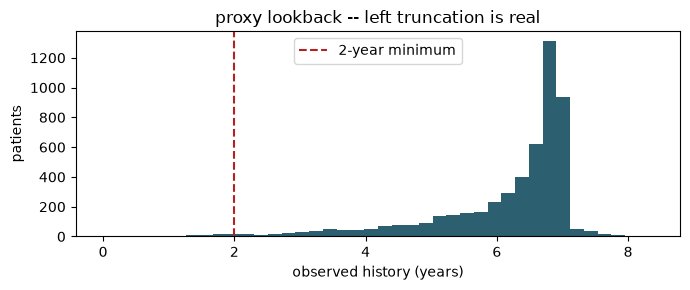


81 patients (1.5%) have under 2 years of history.
Exclude them from any analysis that depends on the ABSENCE of a code.


In [4]:
# How much history do we actually have per patient? (See point 4 above --
# this is the proxy lookback window, not a true observation period.) The
# 2-year line is a common minimum bar for "long enough history to trust an
# absence of a code."
win = eo.observation_window(events)
print(win.lookback_days.describe().round(0).to_string())

plt.figure(figsize=(7, 3))
plt.hist(win.lookback_days / 365.25, bins=40, color='#2C5F6F')
plt.axvline(2, ls='--', c='firebrick', label='2-year minimum')
plt.xlabel('observed history (years)'); plt.ylabel('patients')
plt.title('proxy lookback -- left truncation is real'); plt.legend()
plt.tight_layout(); plt.show()

SHORT = win.loc[win.lookback_days < 730, 'person_id']
print(f"\n{len(SHORT)} patients ({len(SHORT)/len(win):.1%}) have under 2 years of history.")
print("Exclude them from any analysis that depends on the ABSENCE of a code.")

## 2 · Concept sets, resolved by name

**Goal:** show how a clinical concept like "letrozole" turns into an actual, checkable list of medical codes — and why we resolve it by *name* instead of hand-typing code numbers.

`CODESETS` in `ethos_omop.py` maps a clinical label to name patterns plus vocabularies.
Resolving by name rather than hardcoding concept_ids means the same notebook runs against
real Snowflake concepts and the demo extract alike.

*In plain terms: instead of writing down a fixed list of magic numbers ("code 19022830 means letrozole"), we write down a search pattern ("anything whose name matches 'letrozole' in the RxNorm vocabulary") and let the computer look up the matching codes every time. That way the same notebook keeps working even if the underlying code numbers differ between data sources.*

**Always eyeball the resolution before trusting it.** This is the step where a bad regex
quietly poisons everything downstream.

In [5]:
# Eyeball it: what did the "letrozole" pattern actually match? One row here
# means one specific product code -- exactly what you want to see before
# trusting anything downstream.
eo.resolve(concept, ['letrozole'], vocabularies=['RxNorm', 'RxNorm Extension'])

,concept_id,concept_name,vocabulary_id,concept_code,domain_id
7978,19022830,letrozole 2.5 MG Oral Tablet,RxNorm,200064,Drug
894,1315947,letrozole 2.5 MG Oral Tablet [Femara],RxNorm,153124,Drug


In [6]:
# Medical coding systems are hierarchical: a drug "ingredient" (letrozole)
# can have several branded/dosed "products" under it, and a diagnosis can
# have several more specific children. `concept_ancestor` lets us walk that
# hierarchy in either direction.

# On real data, roll a drug ingredient DOWN to all its products via concept_ancestor.
lz = codesets['letrozole']
print("letrozole concepts, direct:      ", len(lz))
print("letrozole concepts, + descendants:", len(eo.expand_descendants(lz)))

# And roll an unspecified diagnosis UP to its parents -- e.g. `breast_cancer`,
# the comorbidity marker that distinguishes this cohort's oncology-indication
# subgroup (letrozole is the anchor here, not breast_cancer -- see Table 1).
bc = codesets['breast_cancer']
print("breast cancer parents, 1 level up:  ", len(eo.roll_up(bc, levels=1)))

letrozole concepts, direct:       2
letrozole concepts, + descendants: 2
breast cancer parents, 1 level up:   1


In [7]:
# `tag` collapses many concept_ids into one readable clinical label.
# Untagged events fall back to a slug of concept_name so sequences stay legible.
# What are the most common tags overall, and what fraction of all events
# actually got one of our curated labels versus falling back to a raw name?
print(events.tag.value_counts().head(15).to_string())
print(f"\ntagged into a codeset: {events.in_codeset.mean():.1%}")

tag
venipuncture_for_blo__procedure__4102442         39904
letrozole_25_mg_oral__clinical_drug__19022830    19760
progesterone_measure__procedure__4263754         17686
estradiol_total__cpt4__2212320                   16366
therapeutic_procedur__cpt4__2314284              16126
psychotherapy_60_min__cpt4__43527905             15715
gonadotropin_chorion__cpt4__2212631              14214
manual_therapy_techn__cpt4__2314290              13609
female_infertility__disorder__201909             13591
low_back_pain__clinical_finding__194133          12978
transvaginal_echogra__procedure__4027510         12128
generalized_anxiety___disorder__434613           11785
chiropractic_manipul__cpt4__2314331              11573
complete_blood_count__procedure__4319466         10829
thyroid_stimulating___procedure__4246879         10724

tagged into a codeset: 8.9%


Roughly a quarter to a third of events land in a curated codeset. That ratio is normal and
it is a useful number to report: it quantifies how much of the record your hand-built
domain knowledge actually covers. Zack's unknown-unknowns objection is exactly the other
two thirds.

*In plain terms: we only defined clinical labels (letrozole, mastectomy, breast_cancer, ...) for the codes relevant to this specific question. Everything else in a patient's record still exists in the data, we just haven't given it a friendly name -- it isn't lost, and it's part of what later, more automated methods (Day 4's embeddings) can pick up on that our hand-picked labels can't.*

## 3 · The bag of codes, and the exact failure

**Goal for this section:** build the simplest possible patient representation — a checklist of which codes each patient has — and then show exactly where it breaks.

In [8]:
# The "bag of codes": one row per patient, one column per code, 1 if the
# patient ever had that code and 0 if not. This throws away *when* things
# happened and *how many times* -- it's the simplest representation there
# is, and the one we're about to show fails.
X = eo.bag_of_codes(events, min_count=20)
print(X.shape)
X.iloc[:5, :8]

(5238, 4223)


tag,025_mg_05_mg_dose_15__branded_drug__793152,025_mg_05_mg_dose_3___branded_drug__741834,02_ml_sarscov2_covid__quant_branded_drug__37355138,036_ml_follitropin_b__quant_branded_drug__43011837,03_ml_enoxaparin_sod__quant_clinical_drug__40160970,03_ml_sarscov2_covid__quant_branded_drug__1735839,03_ml_sarscov2_covid__quant_branded_drug__37355134,03_ml_sarscov2_covid__quant_branded_drug__747830
person_id,,,,,,,,
1949,0,0,0,0,0,0,0,0
4358,0,0,0,0,0,0,0,0
4531,0,0,0,0,0,0,0,0
5216,0,0,0,0,0,0,0,0
5294,0,0,0,0,0,0,0,0


**Goal:** get a feel for `X` before we do anything clever with it — which codes are common, which are rare, and how that's different from what an NMF component (two sections down) will tell us.

Prevalence read directly off `X`, before any factorization -- contrasted with the NMF-loading readout two sections down. A loading tells you what's characteristic of a *component*, not how common a code is overall: `letrozole` is ~100% prevalent here yet won't dominate any single NMF component once it's dropped as near-constant.

*In plain terms: "prevalence" here just means "what % of patients have this code at all." That's a different question from "which codes define this cluster/component" -- a code can be common across the whole cohort (like `letrozole`, since that's how the cohort was defined) without being distinctive of any particular subgroup.*

4223 codes, prevalence range 0.019% - 99.847%


,prevalence
tag,
letrozole_25_mg_oral__clinical_drug__19022830,99.8%
venipuncture_for_blo__procedure__4102442,63.6%
thyroid_stimulating___procedure__4246879,48.9%
complete_blood_count__procedure__4319466,47.9%
gynecologic_examinat__procedure__4306780,42.9%
comprehensive_metabo__procedure__3661905,42.8%
hemoglobin_a1c_measu__procedure__4184637,41.5%
gonadotropin_chorion__cpt4__2212631,40.5%
transvaginal_echogra__procedure__4027510,40.3%


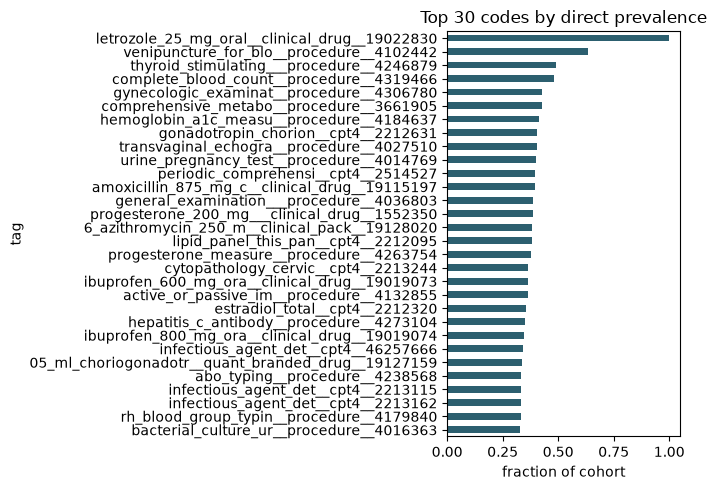

In [9]:
# How common is each code across the whole cohort? (Just column-wise
# averages of the 0/1 matrix above -- no modelling yet.)
prevalence = X.mean().sort_values(ascending=False)
print(f"{len(prevalence)} codes, prevalence range "
      f"{prevalence.min():.3%} - {prevalence.max():.3%}")
display(prevalence.head(20).to_frame('prevalence').style.format('{:.1%}'))

plt.figure(figsize=(7, 5))
prevalence.head(30).iloc[::-1].plot.barh(color='#2C5F6F')
plt.xlabel('fraction of cohort'); plt.title('Top 30 codes by direct prevalence')
plt.tight_layout(); plt.show()

### Choosing `min_count` from prevalence

`bag_of_codes(min_count=...)` counts **events**, so one patient with 20 refills keeps a code alive. What limits a model is how many **patients** carry a code, so this cell works in patients.

*In plain terms: a code in only a handful of patients can't form a reliable pattern, but dropping too many throws away signal. The table shows what each cutoff costs and suggests one.*

The suggested floor is `ceil(MIN_TRAIN_PATIENTS * cohort / N_TRAIN)`: the patients a code needs so a training split is expected to hold at least `MIN_TRAIN_PATIENTS` of them. It scales with cohort size and is a heuristic, not a test.

,prevalence_%,columns,pairs_kept_%
rule,,,
>= 1 patients,0.0191,11001,100.00
>= 2 patients,0.0382,7869,99.40
>= 5 patients,0.0955,5250,98.04
>= 10 patients,0.1909,3786,96.20
>= 20 patients,0.3818,2695,93.34
>= 35 patients,0.6682,1980,89.85
>= 50 patients,0.9546,1619,87.02
>= 100 patients,1.9091,1069,79.62
>= 200 patients,3.8183,601,67.06


cohort 5238 patients, training split 3142
suggested floor: 9 patients (0.172% prevalence) -> 3979 of 11001 columns, 96.5% of patient-code pairs kept
codeset tags below the floor: none


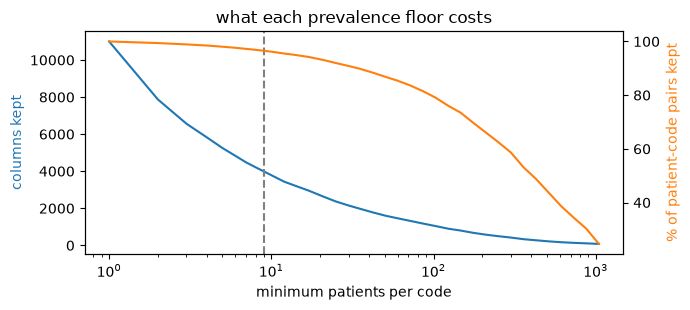


To apply it, build X from the kept codes only (min_count=1 on pre-filtered events):
    X = eo.bag_of_codes(events[events.tag.isin(KEEP_TAGS)], min_count=1)


In [10]:
import math

MIN_TRAIN_PATIENTS = 5            # a code should appear in >= this many patients of a training split
n_pat   = events.person_id.nunique()
N_TRAIN = min(20_000, int(0.6 * n_pat))      # training-split size used by the k-sweep cells

# patients per code, and events per code (what bag_of_codes' min_count counts)
code, tags = pd.factorize(events['tag'])
key        = events['person_id'].to_numpy(np.int64) * len(tags) + code
prev_pat   = pd.Series(np.bincount(np.unique(key) % len(tags), minlength=len(tags)), index=tags)
ev_cnt     = pd.Series(np.bincount(code, minlength=len(tags)), index=tags)
all_pairs  = int(prev_pat.sum())             # distinct (patient, code) pairs = ones in the full 0/1 matrix

def summarize(mask):
    return {'columns': int(mask.sum()),
            'pairs_kept_%': round(100 * prev_pat[mask].sum() / all_pairs, 2)}

rows = [{'rule': f'>= {p} patients', 'prevalence_%': round(100 * p / n_pat, 4), **summarize(prev_pat >= p)}
        for p in [1, 2, 5, 10, 20, 35, 50, 100, 200, 500]]
rows.append({'rule': 'current min_count=20 (events)', 'prevalence_%': np.nan, **summarize(ev_cnt >= 20)})
rule_tbl = pd.DataFrame(rows).set_index('rule')

MIN_PATIENTS = math.ceil(MIN_TRAIN_PATIENTS * n_pat / N_TRAIN)
KEEP_TAGS    = prev_pat.index[prev_pat >= MIN_PATIENTS]
display(rule_tbl)

# the clinical (codeset) tags are the ones the analysis is about -- do any fall below the floor?
codeset_tags = [t for t in codesets if t in prev_pat.index]
lost = prev_pat[codeset_tags][lambda s: s < MIN_PATIENTS]
print(f"cohort {n_pat} patients, training split {N_TRAIN}")
print(f"suggested floor: {MIN_PATIENTS} patients ({100 * MIN_PATIENTS / n_pat:.3f}% prevalence) -> "
      f"{len(KEEP_TAGS)} of {len(prev_pat)} columns, "
      f"{100 * prev_pat[KEEP_TAGS].sum() / all_pairs:.1f}% of patient-code pairs kept")
print("codeset tags below the floor:", lost.to_dict() if len(lost) else "none")

fig, ax = plt.subplots(figsize=(7, 3.2))
ps = np.unique(np.round(np.geomspace(1, max(2, prev_pat.max() / 5), 40)).astype(int))
ax.plot(ps, [(prev_pat >= p).sum() for p in ps], color='C0')
ax.set_xscale('log'); ax.set_xlabel('minimum patients per code'); ax.set_ylabel('columns kept', color='C0')
ax2 = ax.twinx()
ax2.plot(ps, [100 * prev_pat[prev_pat >= p].sum() / all_pairs for p in ps], color='C1')
ax2.set_ylabel('% of patient-code pairs kept', color='C1')
ax.axvline(MIN_PATIENTS, ls='--', c='grey')
ax.set_title('what each prevalence floor costs')
plt.tight_layout(); plt.show()

print("\nTo apply it, build X from the kept codes only (min_count=1 on pre-filtered events):")
print("    X = eo.bag_of_codes(events[events.tag.isin(KEEP_TAGS)], min_count=1)")

In [11]:
X = eo.bag_of_codes(events[events.tag.isin(KEEP_TAGS)], min_count=1)
print(X.shape)

(5238, 3979)


In [12]:
# The punchline of the whole notebook: find one letrozole+breast_cancer
# patient labelled "fertility" and one labelled "oncology" by the rule-based
# check below, then show that the bag-of-codes view (X) can't tell them
# apart at all, even though their real timelines obviously can.
weak = eo.weak_labels(events)                      # rule-based probe labels
lab  = weak.set_index('person_id').weak_label

_eg = events[events.groups.notna()]
Xg = eo.bag_of_codes(_eg.assign(group=_eg.groups.astype(str).str.split('|')).explode('group').reset_index(drop=True), col='group', min_count=1)   # group-level checklist (a concept counts in EVERY group it is in), demo only
both = [p for p in X.index
        if Xg.loc[p].get('letrozole', 0) == 1
        and Xg.loc[p].get('breast_cancer', 0) == 1
        and p in lab.index]

a = next((p for p in both if lab[p] == 'fertility'), None)
b = next((p for p in both if lab[p] == 'oncology'),  None)
assert a and b, ("No identical-bag pair found in this sample. Increase the extract "
                 "size, or inspect `both` to see which side is missing.")

# Same view, plus a few randomly-picked columns where they DO differ -- shown
# side by side so it's clear these two patients aren't identical everywhere,
# just on the two columns that matter for the fertility-vs-oncology question.
diff_cols_all = X.columns[X.loc[a] != X.loc[b]]
diff_cols = list(pd.Index(diff_cols_all).to_series()
                  .sample(n=min(3, len(diff_cols_all)), random_state=0))
print("bag-of-codes view -- identical on letrozole/breast_cancer, "
      f"differs on {diff_cols}:")
display(pd.concat([Xg, X], axis=1).loc[[a, b], ['letrozole', 'breast_cancer'] + diff_cols])

print("\nactual timelines -- obviously different:")
# FOCUS = eo.FERTILITY_TAGS / eo.ONCOLOGY_TAGS -- the same constants
# weak_labels() used to build `lab` -- plus the exposure/anchor tags, so this
# timeline shows the full evidence base behind the label instead of a
# hand-picked subset that can drift from it. Tags that never occurred for a
# given patient simply produce no row below, so this costs nothing visually.
FOCUS = ['letrozole', 'breast_cancer'] + eo.FERTILITY_TAGS + eo.ONCOLOGY_TAGS
for pid in (a, b):
    s = events[(events.person_id == pid) & eo.group_mask(events, FOCUS)]
    print(f"\n  person_id {pid}  ({lab[pid]})")
    print(s[['event_date', 'groups', 'tag']].drop_duplicates('tag').to_string(index=False))

letrozole patients: 5238   labelled: 3835   both-evidence (dropped): 484   no-evidence (dropped): 919
bag-of-codes view -- identical on letrozole/breast_cancer, differs on ['colonoscopy_flexible__cpt4__2109201', 'prednisone_20_mg_ora__clinical_drug__1551170', 'unlisted_procedure_n__cpt4__2110900']:


,letrozole,breast_cancer,colonoscopy_flexible__cpt4__2109201,prednisone_20_mg_ora__clinical_drug__1551170,unlisted_procedure_n__cpt4__2110900
person_id,,,,,
4460222,1,1,0,1,0
308016,1,1,1,0,1



actual timelines -- obviously different:

  person_id 4460222  (fertility)
event_date         groups                                           tag
2021-04-22 pregnancy_test      urine_pregnancy_test__procedure__4014769
2025-06-21      letrozole letrozole_25_mg_oral__clinical_drug__19022830
2026-07-24  breast_cancer       primary_malignant_ne__disorder__4162253

  person_id 308016  (oncology)
event_date               groups                                           tag
2022-02-08       receptor_assay           immunohistochemistry__cpt4__2213300
2022-02-08       receptor_assay          immunohistochemistry__cpt4__46257426
2022-04-21       receptor_assay           special_stain_includ__cpt4__2213288
2023-06-08        breast_cancer       primary_malignant_ne__disorder__4162253
2023-06-08 lymph_node_procedure           injection_procedure___cpt4__2108492
2023-06-08           mastectomy         simple_mastectomy__procedure__4066543
2023-06-08 lymph_node_procedure          intraoperative_id

**That is the motivation for the whole week.** Identical features, opposite risk. The
information lives in the order, and the representation threw it away.

This is not a modelling failure. No estimator can recover something the input does not
contain.

*In plain terms: this isn't a case of "use a fancier algorithm and it'll figure it out." The bag-of-codes table literally does not contain the information needed to tell these two patients apart -- both rows are 1, 1. No amount of machine learning can pull a distinction out of data where the distinction was never recorded in the first place. You have to fix the representation, not the model.*

### On `weak_labels()`

**Goal:** since there's no ground-truth "this patient took letrozole for fertility / for cancer" label in claims data, build a trustworthy *stand-in* label we can use to check our work — and be upfront about how it's built and where it can go wrong.

There are no adjudicated labels in claims data. `weak_labels()` builds probe labels for the
letrozole indication from **corroborating co-evidence only** — clomiphene, gonadotropins and
infertility diagnoses on one side; mastectomy, biopsy, tamoxifen and anastrozole on the
other. Patients with both kinds of evidence, or neither, are dropped, and the counts are
printed so you can see how many.

*In plain terms: instead of guessing the reason for letrozole directly, we look for other, more specific evidence nearby — did the patient also have a fertility drug or an infertility diagnosis? Did they also have a mastectomy or a cancer drug? If the evidence points clearly one way, we use that as the label. If it points both ways, or neither way, we honestly say "we don't know" and drop them rather than force a guess.*

**The time delta is deliberately not used.** If you label by "drug before diagnosis" and
then test whether the time delta predicts the label, you get perfect accuracy by
construction and have learned nothing. These labels are for evaluation, never features.

*In plain terms: it would be tempting to say "letrozole came before the cancer diagnosis, so it must be fertility-related." But that's using the very thing we're trying to test (timing) to build the answer key -- then "discovering" that timing predicts the answer would be circular, not a real finding. So the answer key is built from a different, independent kind of evidence, and timing is only used afterward to see if it can predict that answer.*

## 4 · Distance metrics disagree

**Goal:** show that "how similar are two patients" isn't one universal number — the metric you pick changes the answer, and picking the wrong one for claims data quietly breaks everything downstream.

In [13]:
from sklearn.metrics import pairwise_distances
import scipy.sparse as sp

# letrozole is the cohort anchor here -- 100% prevalence (confirmed below), so
# it's a constant column that carries no discriminative signal and would just
# eat a component. Drop it before any distance/SVD/NMF fit; X itself (with
# the column) stays untouched for the two-patient demo above.
# Everything downstream works on a SPARSE copy (Xs): same values as the dense matrix without the
# anchor column, a fraction of the memory, and faster NMF / SVD.
nmf_cols = X.columns[~X.columns.isin(events.loc[eo.group_mask(events, 'letrozole'), 'tag'])]                   # code names for the components
n_pat    = X.shape[0]
Xs = sp.csr_matrix(X.to_numpy())[:, X.columns.get_indexer(nmf_cols)].astype(float).tocsr()
print(f"Xs {Xs.shape}, density {Xs.nnz / (Xs.shape[0] * Xs.shape[1]):.3%}")

def dist_to_all(row, M, metric, chunk=10_000):
    """Distances from one row to every row of sparse M, densifying only `chunk` rows at a time."""
    return np.concatenate([pairwise_distances(row, M[i:i + chunk].toarray(), metric=metric)[0]
                           for i in range(0, M.shape[0], chunk)])

# First: pick 400 random patients and measure how "far apart" every pair is,
# under two different definitions of distance. If cosine and jaccard disagree
# on how spread out the cohort is, that's a sign the metric matters, not just
# the data.
sub = Xs[:400].toarray()
for m in [#'euclidean', 
          'cosine', 'jaccard']:
    D  = pairwise_distances(sub, metric=m)
    iu = np.triu_indices(len(sub), 1)
    print(f"{m:10s} mean={D[iu].mean():.3f}  sd={D[iu].std():.3f}")

# Second: for one specific patient (`a`, our fertility case from the demo
# above), who are their 5 nearest neighbours under each metric, and what
# weak label do those neighbours carry? Also report the direct a<->b
# distance, since b (the oncology case) is exactly the contrast we want.
posa = list(X.index).index(a)
posb = list(X.index).index(b)
print()
for m in [#'euclidean', 
          'cosine', 'jaccard']:
    D  = dist_to_all(Xs[posa:posa+1].toarray(), Xs, m)
    nn = [X.index[i] for i in np.argsort(D)[1:6]]
    print(f"{m:10s} neighbours of {a}: {[lab.get(p, '?') for p in nn]}")
    print(f"{m:10s} distance({a}, {b}) = {D[posb]:.3f}")

Xs (5238, 3977), density 2.406%
cosine     mean=0.869  sd=0.076
jaccard    mean=0.934  sd=0.044



/opt/miniconda3/envs/ethos_llm/lib/python3.13/site-packages/sklearn/metrics/pairwise.py:2480: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


cosine     neighbours of 4460222: ['?', 'fertility', 'fertility', 'fertility', '?']
cosine     distance(4460222, 308016) = 0.812
jaccard    neighbours of 4460222: ['?', 'fertility', 'fertility', '?', '?']
jaccard    distance(4460222, 308016) = 0.897


/opt/miniconda3/envs/ethos_llm/lib/python3.13/site-packages/sklearn/metrics/pairwise.py:2480: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


**Rule of thumb for claims: use cosine on binary or count code vectors.** Euclidean punishes
patients simply for having long histories, so the distance ends up driven by utilisation
volume rather than clinical content — which in your data is partly a function of what got
ordered during underwriting.

*In plain terms: a patient with 200 recorded codes isn't automatically "less similar" to everyone else than a patient with 20 codes — but a naive distance metric (Euclidean) treats it that way, because it's sensitive to how many codes are turned on, not just which ones. Cosine distance cares about the pattern of codes, not the raw count, which is what we actually want to compare.*

## 5 · The curse of dimensionality

**Goal:** show why "just add more codes" eventually backfires — past a certain number of columns, distance stops being meaningful at all.

On the full Ethos vocabulary you will have tens of thousands of columns, not the few dozen
here. At that width every pair of patients becomes equidistant and "nearest neighbour" stops
meaning anything.

*In plain terms: with only a handful of columns, "similar" and "different" are easy to tell apart. Once you have tens of thousands of columns and each patient only has a handful of them turned on, almost every pair of patients ends up looking roughly equally (dis)similar to each other -- there's no longer a meaningful "close" versus "far." This is a general math fact (the "curse of dimensionality"), not something specific to our data.*

In [14]:
# Not our data -- pure demonstration. Make random sparse 0/1 tables (2% of
# cells "on", like real code data) of increasing width, and watch the ratio
# of the closest pair's distance to the farthest pair's distance collapse
# toward 1 as width grows. That's the curse of dimensionality happening in
# front of you, independent of anything about breast cancer or letrozole.
rng = np.random.default_rng(0)
print(f"{'dims':>6} {'min/max distance ratio':>24}")
for d in [10, 50, 200, 1000, 5000]:
    Zr = (rng.random((200, d)) < 0.02).astype(float)     # sparse, like code data
    D  = pairwise_distances(Zr)
    iu = np.triu_indices(200, 1)
    print(f"{d:>6} {D[iu].min() / D[iu].max():>24.3f}")
print("\nRatio -> 1 means every patient is equally far from every other.")

  dims   min/max distance ratio
    10                    0.000
    50                    0.000
   200                    0.000
  1000                    0.568
  5000                    0.782

Ratio -> 1 means every patient is equally far from every other.


## 6 · Truncated SVD and NMF

**Goal:** compress thousands of sparse code columns down into a handful of numbers per patient that are actually usable for distance/clustering/visualization — and see two different ways of doing that compression.

*In plain terms: both methods below take the wide, sparse `X` table (thousands of mostly-zero columns) and produce a much narrower table (a few dozen columns) that still captures most of the real signal. Think of it as automatic summarization of a patient's code history into a small number of "themes." SVD and NMF differ in what kind of themes they're allowed to produce -- that difference is exactly why we look at both.*

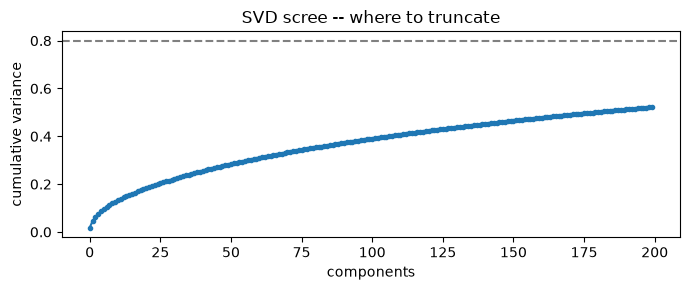

In [15]:
from sklearn.decomposition import TruncatedSVD, NMF
from sklearn.preprocessing import normalize

# SVD finds the directions that explain the most variation in the data --
# similar in spirit to PCA. Its components can be positive or negative and
# don't have a clean "these codes belong to this theme" reading, but they're
# a solid general-purpose compression. Normalize first so this lines up with
# the cosine geometry we already decided was the right one for this data.
Xn  = normalize(Xs)                                  # cosine geometry, done properly
svd = TruncatedSVD(n_components=min(200, Xs.shape[1] - 1), random_state=0).fit(Xn)
Z   = svd.transform(Xn)

# How many components until we've captured most of the signal? The scree
# plot below answers that -- steep rise then flattening out means most of
# what matters is in the first handful of components.
plt.figure(figsize=(7, 3))
plt.plot(np.cumsum(svd.explained_variance_ratio_), marker='o', ms=3)
plt.axhline(0.8, ls='--', c='grey')
plt.xlabel('components'); plt.ylabel('cumulative variance')
plt.title('SVD scree -- where to truncate'); plt.tight_layout(); plt.show()

### Choosing k for the NMF

This sweep puts numbers on the choice of k: held-out error, silhouette, and bootstrap ARI, as Day 2 does for KMeans.

*In plain terms: fit the NMF at several k. For each, check how well it explains unseen patients, how well separated the groups are, and whether the same bundles return on re-draws. Pick the k where extra components stop paying off but the bundles stay reproducible.*

- Every k is fit on the same `N_SWEEP` patients and scored on a disjoint `N_HELD` set.
- Silhouette is computed in the SVD space `Z` that Day 2 used, not in NMF's loading space, which would be circular.
- The sweep repeats on every split in `SPLIT_SEEDS`, each with `N_BOOT_K` bootstrap refits per k. Several splits show whether a k only looks stable because of the patients drawn.
- All fits share `NMF_KW`. They run in parallel on a sparse copy of the matrix, `Xs`.

In [16]:
import time
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import adjusted_rand_score

# one place for the NMF fit settings, used by every NMF fit in this section
NMF_KW = dict(init='nndsvd', random_state=0, max_iter=2000, tol=1e-4)

N_BOOT        = 10        # refits; each is a full NMF fit, raise once you know the runtime
N_BOOT_SAMPLE = 20_000    # patients per resample (capped at the cohort size)
N_EVAL        = 20_000    # fixed patients used to compare argmax labels (capped)

def _unit(M):
    return M / np.linalg.norm(M, axis=1, keepdims=True)

def nmf_stability(nmf_base, Xv, n_boot=N_BOOT, n_sample=N_BOOT_SAMPLE,
                  n_eval=N_EVAL, seed=0):
    """Bootstrap-refit NMF; return per-component matched cosine and per-boot ARI.

    Component order is arbitrary between fits (label switching), so each refit's
    components are matched to the base fit's by cosine similarity (Hungarian
    algorithm). ARI compares argmax patient partitions, which needs no matching.
    """
    k    = nmf_base.n_components_
    Hb   = _unit(nmf_base.components_)
    rng  = np.random.default_rng(seed)
    ev   = rng.choice(Xv.shape[0], min(n_eval, Xv.shape[0]), replace=False)
    lab0 = nmf_base.transform(Xv[ev]).argmax(1)
    cos, ari = [], []
    for b in range(n_boot):
        t0  = time.perf_counter()
        idx = rng.choice(Xv.shape[0], min(n_sample, Xv.shape[0]), replace=True)
        m   = NMF(n_components=k, **NMF_KW).fit(Xv[idx])
        S        = Hb @ _unit(m.components_).T         # base x refit cosine
        rows, cols = linear_sum_assignment(-S)          # rows come back sorted 0..k-1
        cos.append(S[rows, cols])                       # cos[b][j] = base component j
        ari.append(adjusted_rand_score(lab0, m.transform(Xv[ev]).argmax(1)))
        print(f"  boot {b + 1}/{n_boot}  {time.perf_counter() - t0:.0f}s  "
              f"ARI {ari[-1]:.3f}")
    return np.array(cos), np.array(ari)


[Parallel(n_jobs=12)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  50 out of  60 | elapsed:   34.7s remaining:    6.9s


60 jobs on 12 workers; summed fit time 6.8 CPU-min


[Parallel(n_jobs=12)]: Done  60 out of  60 | elapsed:   37.6s finished


,held_out_err,silhouette,ari_mean,ari_sd_splits,n_splits_solid,n_splits_sugg,cos_mean,n_unstable,n_used
k,,,,,,,,,
3,0.884,0.096,0.802,0.052,4,5,0.986,0.0,3
4,0.878,0.087,0.791,0.118,4,4,0.954,0.0,4
5,0.872,0.095,0.862,0.019,5,5,0.988,0.0,5
6,0.867,0.084,0.830,0.041,5,5,0.976,0.0,6
7,0.863,0.080,0.832,0.022,5,5,0.981,0.0,7
8,0.860,0.075,0.749,0.055,2,5,0.963,0.0,8
9,0.857,0.070,0.670,0.034,0,5,0.935,0.0,9
10,0.854,0.064,0.739,0.051,3,5,0.965,0.0,10
11,0.851,0.059,0.691,0.041,0,5,0.919,1.0,11


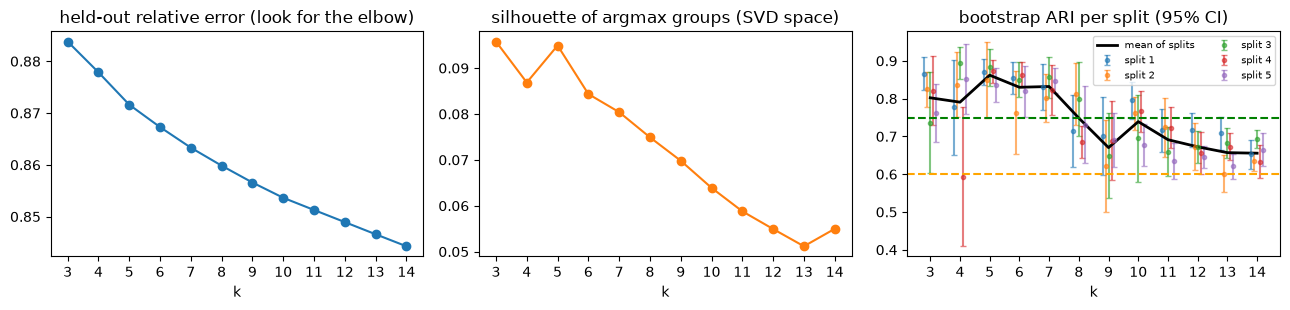

largest k with ARI >= 0.60 on 4+ of 5 splits and mean cos >= 0.75: 14
largest k with ARI >= 0.75 on 4+ of 5 splits and no unstable component (median): 7


In [17]:
import time
import io, contextlib
import os, math
import scipy.sparse as sp
from joblib import Parallel, delayed
from sklearn.metrics import silhouette_score
from scipy import stats

K_GRID      = list(range(3, 15))
SPLIT_SEEDS = (1, 2, 3, 4, 5)   # independent train / held-out splits of the cohort
N_SWEEP     = min(20_000, int(0.6 * Xs.shape[0]))   # train patients every k is fit on (scales with the cohort)
N_HELD      = min(10_000, Xs.shape[0] - N_SWEEP)    # disjoint held-out patients for error / silhouette
N_BOOT_K    = 10          # bootstrap refits per k and split (reuses nmf_stability above)
NC_SIL      = min(24, Z.shape[1])   # SVD dims Day 2 scored KMeans silhouette in
MIN_SPLITS_OK = math.ceil(0.8 * len(SPLIT_SEEDS))   # a k must pass on this many splits (4 of 5)
N_JOBS      = max(1, (os.cpu_count() or 2) - 2)   # sklearn's NMF is single-threaded: one fit per core

def rel_err(X, W, H):
    """||X - W H||_F / ||X||_F without building the dense W @ H (X may be sparse)."""
    x2    = X.multiply(X).sum() if sp.issparse(X) else (X ** 2).sum()
    cross = np.sum((X @ H.T) * W)
    quad  = np.sum((W.T @ W) * (H @ H.T))
    return float(np.sqrt(max(x2 - 2 * cross + quad, 0.0) / x2))

def sweep_job(split_seed, k, Xtr, Xho, Zho, n_boot):
    """All metrics for one (split, k): one base fit plus n_boot bootstrap refits."""
    t0 = time.perf_counter()
    m  = NMF(n_components=k, **NMF_KW).fit(Xtr)
    Wh = m.transform(Xho)
    lab_ho = Wh.argmax(1)
    with contextlib.redirect_stdout(io.StringIO()):          # silence per-boot prints
        cos, ari = nmf_stability(m, Xtr, n_boot=n_boot, n_sample=Xtr.shape[0],
                                 n_eval=Xtr.shape[0], seed=k)
    share = np.bincount(lab_ho, minlength=k) / len(lab_ho)
    return {'split': split_seed, 'k': k,
            'held_out_err': rel_err(Xho, Wh, m.components_),
            'silhouette': silhouette_score(Zho, lab_ho) if len(set(lab_ho)) > 1 else np.nan,
            'ari_mean': ari.mean(), 'ari_sd': ari.std(ddof=1),
            'ari_se': ari.std(ddof=1) / np.sqrt(n_boot),
            'cos_mean': cos.mean(), 'n_unstable': int((cos.mean(0) < .75).sum()),
            'n_used': int((share >= .01).sum()), 'secs': time.perf_counter() - t0}

def make_split(split_seed):                                   # sliced once here, so workers get small inputs
    perm   = np.random.default_rng(split_seed).permutation(Xs.shape[0])
    tr, ho = perm[:N_SWEEP], perm[N_SWEEP:N_SWEEP + N_HELD]
    return Xs[tr], Xs[ho], Z[ho, :NC_SIL]                     # Z rows align with Xs rows

splits  = {s: make_split(s) for s in SPLIT_SEEDS}
jobs    = [(s, k) for k in sorted(K_GRID, reverse=True) for s in SPLIT_SEEDS]   # slow (large k) first
results = Parallel(n_jobs=N_JOBS, verbose=5)(
              delayed(sweep_job)(s, k, *splits[s], N_BOOT_K) for s, k in jobs)
res       = pd.DataFrame(results)
per_split = {s: res[res.split == s].drop(columns=['split', 'secs']).set_index('k').sort_index()
             for s in SPLIT_SEEDS}
print(f"{len(jobs)} jobs on {N_JOBS} workers; summed fit time {res.secs.sum() / 60:.1f} CPU-min")

# one row per k, summarised over splits
g     = pd.concat(per_split, names=['split']).groupby('k')
sweep = pd.DataFrame({'held_out_err': g.held_out_err.mean(), 'silhouette': g.silhouette.mean(),
                      'ari_mean': g.ari_mean.mean(), 'ari_sd_splits': g.ari_mean.std(),
                      'n_splits_solid': g.ari_mean.apply(lambda a: int((a >= .75).sum())),
                      'n_splits_sugg':  g.ari_mean.apply(lambda a: int((a >= .60).sum())),
                      'cos_mean': g.cos_mean.mean(), 'n_unstable': g.n_unstable.median(),
                      'n_used': g.n_used.min()})
display(sweep.round(3))

t_crit = stats.t.ppf(0.975, N_BOOT_K - 1)    # few refits -> t interval, not 1.96
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
ax[0].plot(sweep.index, sweep.held_out_err, marker='o')
ax[0].set_title('held-out relative error (look for the elbow)')
ax[1].plot(sweep.index, sweep.silhouette, marker='o', color='C1')
ax[1].set_title('silhouette of argmax groups (SVD space)')
for i, s in enumerate(SPLIT_SEEDS):                          # small x-offset so splits do not overlap
    d = per_split[s]
    ax[2].errorbar(d.index + (i - (len(SPLIT_SEEDS) - 1) / 2) * 0.1, d.ari_mean,
                   yerr=t_crit * d.ari_se, fmt='o', ms=3, capsize=2, alpha=.6, label=f'split {s}')
ax[2].plot(sweep.index, sweep.ari_mean, 'k-', lw=2, label='mean of splits')
ax[2].axhline(0.75, ls='--', c='green');  ax[2].axhline(0.60, ls='--', c='orange')
ax[2].set_title('bootstrap ARI per split (95% CI)'); ax[2].legend(fontsize=7, ncol=2)
for a in ax: a.set_xlabel('k'); a.set_xticks(sweep.index)
plt.tight_layout(); plt.show()

ok     = sweep[(sweep.n_splits_sugg >= MIN_SPLITS_OK) & (sweep.cos_mean >= .75)]
strong = sweep[(sweep.n_splits_solid >= MIN_SPLITS_OK) & (sweep.n_unstable == 0)]
print(f"largest k with ARI >= 0.60 on {MIN_SPLITS_OK}+ of {len(SPLIT_SEEDS)} splits and mean cos >= 0.75:",
      int(ok.index.max()) if len(ok) else "none")
print(f"largest k with ARI >= 0.75 on {MIN_SPLITS_OK}+ of {len(SPLIT_SEEDS)} splits and no unstable component (median):",
      int(strong.index.max()) if len(strong) else "none")

### Reading the k sweep

- **Held-out error** always falls with k. Look for the elbow.
- **Silhouette** is low in absolute terms and falls with k. Read the shape.
- **`ari_mean`** is the bootstrap ARI averaged over splits and **`ari_sd_splits`** its spread across splits. **`n_splits_solid`** / **`n_splits_sugg`** count splits with ARI at or above 0.75 / 0.60. **`n_unstable`** is the median over splits.
- Prefer the largest k that is solid on at least 4 of 5 splits (`MIN_SPLITS_OK`). If splits disagree, choose on clinical readability and mark any k below 0.75 as suggestive.
- **`n_used`** counts components that dominate at least 1% of held-out patients. A flat `n_used` means redundant components.
- No single column picks k. Choose after the error elbow and before stability collapses, then confirm the components read as distinct clinical bundles.

### Are those components stable? Bootstrap validation of the NMF

Reading the top codes (above) checks whether a component *means* something. It does not
check whether the component would come back on a different sample of patients. This is the
NMF analogue of Day 2's KMeans bootstrap. It validates the last `nmf` fit above.

*In plain terms: re-run the NMF on random re-draws of the patients and see whether the same
code bundles show up. A bundle that keeps reappearing is real structure; one that only
appears for some draws is an accident of which patients were sampled.*

NMF component numbering is arbitrary between fits (component 3 in one run may be component 7
in the next), so each refit's components are first **matched** to the base fit's by cosine
similarity. Two outputs:

1. **Per component:** matched cosine between the base bundle and its refit counterpart.
2. **Cohort level:** ARI between the `argmax` patient labels, comparable with Day 2.

### Reading the stability table

- **`cos_mean` near 1** means the component's code bundle reappears almost unchanged in every
  resample. **Low `cos_mean` or high `cos_sd`** means the bundle depends on which patients
  happened to be drawn, so don't build a rule on it.
- The cosine cut-offs (0.90 solid, 0.75 suggestive) are working heuristics, not standards.
- **Bootstrap ARI** compares the `argmax` patient labels from each refit with the base
  labels, so it is directly comparable with Day 2's KMeans bootstrap ARI (0.75 solid, 0.60
  suggestive). A component can be stable as a *bundle* while the `argmax` *labels* are
  noisy, because soft loadings tie between bundles. High cos with low ARI is that case.
- Each refit resamples patients with replacement (about 63% distinct patients when it draws
  the whole cohort), so this is a slightly pessimistic stability estimate.
- This validates stability, not meaning. Whether a component really is a clinical bundle is
  still the read-the-top-codes judgement above.

In [18]:
int(strong.index.max()) 

7

In [19]:
# NMF factorises into non-negative PARTS, so each component reads as a set of
# co-occurring codes. Unlike SVD components you can name them.
#
# In plain terms: NMF is only allowed to add codes together, never subtract
# them, so each component ends up looking like "a bundle of codes that tend
# to show up together" -- e.g. "chemotherapy + antineoplastic drug" reads
# as an actual clinical bundle, not an abstract direction in space. That's
# why we print the top-5 codes per component below: it's how you check
# whether a component actually means something clinically, or is noise.
#
# We fit twice, at k=5 and k=12, to see how the story changes with more
# components allowed (see the annotated discussion two cells down). Each
# component is also sized -- by dominant-component count and % of the
# cohort -- and each top code is shown with its % share of that component's
# total loading, so you can see at a glance both which bundles are large
# populations and which codes actually drive each one.
# for k in [3, 5, 8, 12]:
for k in [int(strong.index.max()) ]:
    nmf = NMF(n_components=k, **NMF_KW).fit(Xs)
    H   = pd.DataFrame(nmf.components_, columns=nmf_cols)
    lab_k = nmf.transform(Xs).argmax(axis=1)
    dom = pd.Series(lab_k).value_counts().sort_index()
    # save the fit for reuse (Day 3 loads it instead of refitting); the tag keeps cohorts apart
    np.savez(f"nmf_k{k}_letrozole_v3.npz", H=H.to_numpy(), cols=np.array(H.columns, dtype=str),
             pids=X.index.to_numpy(), labels=lab_k)
    print (f"\nNMF with {k} components:")
    for c in range(k):
        n    = int(dom.get(c, 0))
        row  = H.iloc[c]
        top  = row.sort_values(ascending=False).head(10)
        share = (top / row.sum() * 100).round(1)
        codes = [f"{name} ({pct}%)" for name, pct in share.items()]
        print(f"component {c} (n={n}, {n / n_pat * 100:.1f}%): {codes}")


NMF with 7 components:
component 0 (n=775, 14.8%): ['hemoglobin_a1c_measu__procedure__4184637 (1.5%)', 'thyroid_stimulating___procedure__4246879 (1.5%)', 'lipid_panel_this_pan__cpt4__2212095 (1.5%)', 'follicle_stimulating__procedure__4149280 (1.3%)', 'vitamin_d_25hydroxy___procedure__4007831 (1.3%)', 'prolactin_measuremen__procedure__4010412 (1.2%)', 't4_free_measurement__procedure__4196969 (1.2%)', 'venipuncture_for_blo__procedure__4102442 (1.2%)', 'estradiol_total__cpt4__2212320 (1.2%)', 'cytopathology_cervic__cpt4__2213244 (1.1%)']
component 1 (n=1768, 33.8%): ['amoxicillin_875_mg_c__clinical_drug__19115197 (1.3%)', '6_azithromycin_250_m__clinical_pack__19128020 (1.2%)', 'ibuprofen_800_mg_ora__clinical_drug__19019074 (1.1%)', 'fluconazole_150_mg_o__clinical_drug__1754996 (1.1%)', 'prednisone_20_mg_ora__clinical_drug__1551170 (1.0%)', '21_methylprednisolon__clinical_pack__19129398 (1.0%)', 'ondansetron_4_mg_dis__clinical_drug__19005965 (1.0%)', 'ibuprofen_600_mg_ora__clinical_drug__

### Reading the output

**Goal:** check whether these automatically-found components actually mean something clinically, or are just statistical noise — you do that by reading the top-5-codes list per component and asking "does this look like a real clinical group?"


*In plain terms: no deep learning, no neural network -- just three lines of matrix math, and it already recovered groups that make clinical sense (a fertility-medication bundle, a preconception genetic-screening bundle, a pregnancy-outcome bundle). Worth remembering next time someone asks "why not jump straight to a fancy model?"*

### Where do the clinical codes sit? (loadings check)

The top-5 lists can hide a code that matters but is never in a top 5. This cell takes the fertility and oncology evidence tags that `weak_labels()` uses, plus every other codeset, and shows how each code's total loading splits across the components. Each row sums to 100%.

*In plain terms: for each hand-defined clinical code, which bundle owns it, and is it concentrated in one bundle or spread thin?*

`owner` is the component with the largest share. `rank_in_owner` is the code's rank inside that component (1 = its top code). A high share with a rank in the hundreds means the code attaches to the bundle but does not define it. Only codes with a codeset tag appear.

In [20]:
K_CHECK = nmf.n_components_      # the last fit above
H8 = pd.DataFrame(nmf.components_, columns=nmf_cols)
# v3: columns of H8 are concept tokens; a codeset's loading is the SUM over the tokens it groups (a token counts in EVERY codeset it is in)
H8g = eo.group_loadings(H8, events)

# watch list comes from codesets.yaml (via eo), not hand-typed; the cohort anchor is excluded
WATCH = {
    'fertility':      eo.FERTILITY_TAGS,
    'oncology':       eo.ONCOLOGY_TAGS,
    'other codesets': [t for t in eo.CODESETS
                       if t not in eo.FERTILITY_TAGS + eo.ONCOLOGY_TAGS and t != 'letrozole'],
}

rows, missing = [], []
for group, tags in WATCH.items():
    for tag in tags:
        if tag not in H8g.columns or H8g[tag].sum() == 0:
            missing.append(tag); continue
        share = H8g[tag] / H8g[tag].sum() * 100                       # this code's split across components
        own   = int(share.values.argmax())
        rows.append({'group': group, 'code': tag, **{f'c{i}': share.iloc[i] for i in range(K_CHECK)},
                     'owner': own, 'rank_in_owner': int((H8.iloc[own] > H8.iloc[own][H8.columns.intersection(list(eo.group_tokens(events, tag)))].max()).sum() + 1)})

loadings = pd.DataFrame(rows).set_index(['group', 'code'])
comp_cols = [f'c{i}' for i in range(K_CHECK)]
display(loadings.style.format({c: '{:.0f}' for c in comp_cols}).background_gradient(
        axis=1, cmap='Blues', subset=comp_cols))
print("components (n, top code):",
      {i: (int((nmf.transform(Xs).argmax(1) == i).sum()), H8.iloc[i].idxmax()[:28]) for i in range(K_CHECK)})
print("codeset tags with no column (dropped by the prevalence floor, or never occur):", missing or "none")

components (n, top code): {0: (775, 'hemoglobin_a1c_measu__proced'), 1: (1768, 'amoxicillin_875_mg_c__clinic'), 2: (637, 'estradiol_2_mg_oral___clinic'), 3: (858, 'single_live_birth_fr__clinic'), 4: (273, 'cftr_cystic_fibrosis__cpt4__'), 5: (486, 'ondansetron_injectio__clinic'), 6: (441, 'therapeutic_procedur__cpt4__')}
codeset tags with no column (dropped by the prevalence floor, or never occur): ['breast_biopsy', 'antineoplastic_drug', 'metastasis', 'ed_visit']


base fit: NMF k=7  (the `nmf` from the cell above)
  boot 1/10  1s  ARI 0.920
  boot 2/10  1s  ARI 0.909
  boot 3/10  0s  ARI 0.836
  boot 4/10  0s  ARI 0.932
  boot 5/10  0s  ARI 0.905
  boot 6/10  0s  ARI 0.911
  boot 7/10  0s  ARI 0.899
  boot 8/10  0s  ARI 0.932
  boot 9/10  0s  ARI 0.821
  boot 10/10  0s  ARI 0.887


,n,top_codes,cos_mean,cos_sd,cos_min,verdict
0,775,"hemoglobin_a1c_measu__procedure__4184637, thyr...",0.991,0.006,0.977,solid
1,1768,"amoxicillin_875_mg_c__clinical_drug__19115197,...",0.996,0.001,0.994,solid
2,637,"estradiol_2_mg_oral___clinical_drug__1548199, ...",0.993,0.004,0.984,solid
3,858,single_live_birth_fr__clinical_finding__401429...,0.996,0.002,0.989,solid
4,273,"cftr_cystic_fibrosis__cpt4__42742292, ikbkap_i...",0.994,0.001,0.990,solid
5,486,ondansetron_injectio__clinical_drug_form__3560...,0.988,0.003,0.982,solid
6,441,"therapeutic_procedur__cpt4__2314284, manual_th...",0.983,0.004,0.975,solid



bootstrap ARI of argmax labels: mean 0.895  sd 0.036  (Day 2 cut-offs: >=0.75 solid, >=0.60 suggestive)


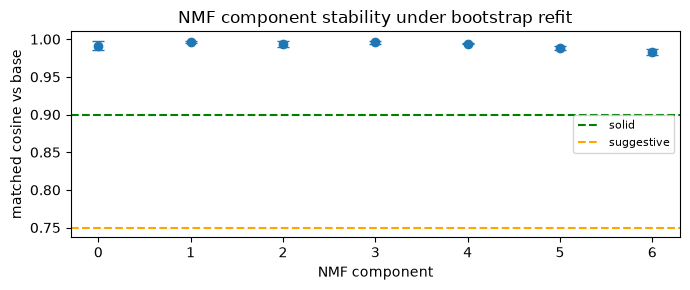

In [21]:
print(f"base fit: NMF k={nmf.n_components_}  (the `nmf` from the cell above)")
cos, ari = nmf_stability(nmf, Xs)

dom_n = pd.Series(nmf.transform(Xs).argmax(1)).value_counts().reindex(range(nmf.n_components_), fill_value=0)
top3  = [', '.join(pd.Series(nmf.components_[c], index=nmf_cols)
                   .nlargest(3).index) for c in range(nmf.n_components_)]
stab = pd.DataFrame({'n': dom_n.values, 'top_codes': top3,
                     'cos_mean': cos.mean(0).round(3), 'cos_sd': cos.std(0).round(3),
                     'cos_min': cos.min(0).round(3)})
stab['verdict'] = np.select([stab.cos_mean >= .90, stab.cos_mean >= .75],
                            ['solid', 'suggestive'], 'unstable')
display(stab)
print(f"\nbootstrap ARI of argmax labels: mean {ari.mean():.3f}  sd {ari.std():.3f}  "
      f"(Day 2 cut-offs: >=0.75 solid, >=0.60 suggestive)")

plt.figure(figsize=(7, 3))
plt.errorbar(stab.index, stab.cos_mean, yerr=stab.cos_sd, fmt='o', capsize=4)
plt.axhline(0.90, ls='--', c='green',  label='solid')
plt.axhline(0.75, ls='--', c='orange', label='suggestive')
plt.xlabel('NMF component'); plt.ylabel('matched cosine vs base')
plt.xticks(stab.index); plt.legend(fontsize=8)
plt.title('NMF component stability under bootstrap refit')
plt.tight_layout(); plt.show()

**NMF bundles as a table** — one row per component for the underwriter review: n (%), the top-5 OMOP entities (name, vocabulary + code, concept_id, share of the bundle's patients) and two empty columns to fill in (pathway, UW suggestion). Written to `nmf_components_<cohort>_k<k>_v3.xlsx`. `RANK_BY = 'prevalence'` ranks by how many of the bundle's patients have the code instead of by NMF loading.

In [ ]:
COHORT = 'letrozole'
# Export the NMF components as a table to review with the underwriters: one row per bundle, the last two columns are left empty to fill in.
import re
try:
    import openpyxl
except ImportError as e:
    raise ImportError("pip install openpyxl in this kernel's environment, then rerun this cell") from e
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter

RANK_BY = 'loading'        # 'loading' = codes that define the bundle (NMF loading); 'prevalence' = codes most patients of the bundle have
TOP_N   = 5
k_exp   = nmf.n_components_
XLSX_NMF = f"nmf_components_{COHORT}_k{k_exp}_v3.xlsx"

lab_e  = nmf.transform(Xs).argmax(1)                                   # dominant component per patient (same rule as the sizes above)
Hc     = pd.DataFrame(nmf.components_, columns=nmf_cols)
meta   = events.drop_duplicates('tag').set_index('tag')

def entity(tok, prev):
    r = meta.loc[tok]
    name = re.split(r' \(|;| This ', str(r.concept_name))[0].strip()
    name = name if len(name) >= 8 else str(r.concept_name)          # packs like '{6 (azithromycin ...) } Pack [Z-PAK]' would be cut to '{6'
    name = name if len(name) <= 60 else name[:60].rsplit(' ', 1)[0] + '…'
    return f"{name} [{r.vocabulary_id} {r.concept_code}] (concept_id {int(r.concept_id)}; {prev:.0%} of bundle)"

rows_e = []
for c in range(k_exp):
    members = np.flatnonzero(lab_e == c)
    prev  = pd.Series(np.asarray(Xs[members].mean(axis=0)).ravel(), index=nmf_cols)     # share of the bundle's patients with each code
    score = Hc.iloc[c] if RANK_BY == 'loading' else prev
    top   = score.nlargest(TOP_N).index
    rows_e.append({'Group': f"c{c}",
                   'n (%)': f"{len(members):,} ({len(members) / len(lab_e):.1%})",
                   'Most frequently OMOP clinical entities found': "\n".join(f"{i}. {entity(t, prev[t])}" for i, t in enumerate(top, 1)),
                   'Suggested Clinical Pathway': '',
                   'UW suggestion': ''})
nmf_table = pd.DataFrame(rows_e)

F = lambda **kw: Font(name='Arial', size=10, **kw)
thin = Side(style='thin', color='D0D5DB')
wb = openpyxl.Workbook(); ws = wb.active; ws.title = f'NMF k={k_exp}'
ws.append(list(nmf_table.columns))
for j in range(1, ws.max_column + 1):
    h = ws.cell(1, j); h.font = Font(name='Arial', size=10, bold=True, color='FFFFFF')
    h.fill = PatternFill('solid', fgColor='334E68'); h.alignment = Alignment(wrap_text=True, vertical='center', horizontal='center')
ws.row_dimensions[1].height = 30
for row in nmf_table.itertuples(index=False):
    ws.append(list(row))
for i in range(2, len(nmf_table) + 2):
    ws.row_dimensions[i].height = 15 * TOP_N + 6
    for j in range(1, ws.max_column + 1):
        c_ = ws.cell(i, j); c_.font = F(bold=(j == 1)); c_.border = Border(bottom=thin)
        c_.alignment = Alignment(wrap_text=True, vertical='top', horizontal='center' if j in (1, 2) else 'left')
for j, w in enumerate([14, 16, 95, 40, 40], 1):
    ws.column_dimensions[get_column_letter(j)].width = w
ws.freeze_panes = 'B2'
ws.cell(len(nmf_table) + 3, 1, f"Source: Day 1 v3 {COHORT}, NMF k={k_exp} on concept-level tokens ({len(lab_e):,} patients). n (%) = patients whose dominant component is the bundle. "
        f"Entities ranked by {'NMF loading in the bundle' if RANK_BY == 'loading' else 'share of the bundle patients having the code'}; "
        "the percentage is the share of the bundle's patients with that code. The last two columns are left empty on purpose.").font = F(italic=True)
wb.save(XLSX_NMF)
print(f"wrote {os.path.abspath(XLSX_NMF)} ({k_exp} bundles)")
nmf_table


wrote /Users/esteban.correaagudelo/codeprojects/ethos_foundation_llm/nb/repr_learn_letrozole/nmf_components_letrozole_k7_v3.xlsx (7 bundles)


,Group (bundle),n (%),Most frequently OMOP clinical entities found,Suggested Clinical Pathway,UW suggestion
0,c0,775 (14.8%),1. Hemoglobin A1c measurement [SNOMED 43396009...,,
1,c1,"1,768 (33.8%)",1. amoxicillin 875 MG / clavulanate 125 MG Ora...,,
2,c2,637 (12.2%),1. estradiol 2 MG Oral Tablet [RxNorm 197659] ...,,
3,c3,858 (16.4%),1. Single live birth from singleton pregnancy ...,,
4,c4,273 (5.2%),1. CFTR (cystic fibrosis transmembrane conduct...,,
5,c5,486 (9.3%),1. ondansetron Injection [RxNorm 1740463] (con...,,
6,c6,441 (8.4%),"1. Therapeutic procedure, 1 or more areas, eac...",,


## Table 1 · Cohort description

**Goal:** produce the kind of summary table a clinical paper would open with — who's in this cohort, broken down a useful way — using the NMF components from above as the breakdown instead of our sparse weak label.

Standard epidemiological Table 1 for the letrozole-exposure cohort: demographics and comorbidity/treatment prevalence as rows, `Overall` plus each NMF component (patients whose *dominant* component is that one) as columns. NMF-component columns give full coverage of the cohort -- unlike the `fertility`/`oncology` weak-label split from `weak_labels()`, which only labelled 4,197 and 90 patients respectively (see the counts above) and left the rest (1,799) unlabelled.

*In plain terms: every patient in the cohort gets sorted into exactly one column, based on which NMF "theme" dominates their record. That gives a real, statistically usable breakdown of the whole cohort -- unlike splitting by the fertility/oncology probe label, which has no opinion about the ~30% of patients whose evidence doesn't point clearly one way. The trailing p-value column tells you, per row, whether that row's value actually differs across those NMF groups, or whether the apparent differences you see could just be noise.*

In [ ]:
# from scipy import stats

# cohort_ids = set(X.index)   # whole letrozole-exposure cohort, not just the oncology subgroup

# # age at first letrozole exposure, from person.birth_date
# lz_index = eo.index_dates(events, 'letrozole').set_index('person_id')['index_date']
# birth    = person.set_index('person_id')['birth_date']
# age_yrs  = (lz_index - birth.reindex(lz_index.index)).dt.days / 365.25

# gender  = person.set_index('person_id')['gender'].astype(str).str.upper()
# win_idx = win.set_index('person_id')['lookback_days']

# # CODE_ROWS wired straight from codesets.yaml (eo.CODESETS) instead of a
# # hand-typed list -- every codeset defined there becomes a row automatically,
# # same mechanism as the breast_cancer cohort notebook, so the two Table 1s
# # are directly comparable row-for-row. 'letrozole' itself is excluded: it's
# # the cohort anchor, tautologically ~100% in every column, not informative.
# CODE_ROWS = sorted(t for t in eo.CODESETS if t != 'letrozole')
# missing = [t for t in CODE_ROWS if t not in codesets]
# assert not missing, f"Table 1 CODE_ROWS not resolved by build_codesets(): {missing}"

# # n_concepts: size of the RESOLVED codeset (post regex + vocabulary match),
# # not the tag's prevalence in `events`. A codeset resolving to 0 concept_ids
# # is a different failure mode than one that resolves fine but simply never
# # occurs in this cohort -- both would otherwise show as a silent 0% below,
# # so flag the unresolved ones loudly instead of leaving that ambiguous.
# n_concepts = {t: len(codesets.get(t, set())) for t in CODE_ROWS}
# unresolved = [t for t, n in n_concepts.items() if n == 0]
# if unresolved:
#     print("WARNING -- these codesets resolved to 0 concept_ids from their yaml "
#           "patterns (0% below means UNRESOLVED, not necessarily absent):")
#     print(" ", unresolved)

# has = {t: set(events.loc[eo.group_mask(events, t), 'person_id']) for t in CODE_ROWS}

# # dominant NMF component per patient, from the NMF already fit above (nmf, Xs, nmf_cols)
# W = nmf.transform(Xs)
# dom_component = pd.Series(W.argmax(axis=1), index=X.index)

# # Labels come from eyeballing the top-5-codes-per-component printout above
# # (cell fc267fef, k=12 fit, with `letrozole` excluded from the NMF input):
# # fertility fragments into medication/monitoring/carrier-screening/pregnancy-
# # outcome arms, the rest are background clinical bundles. Components 1, 3, 5
# # and 7 aren't named -- nothing in their top codes maps cleanly to one of
# # these groups (1 and 3 read as generic pharmacy/antibiotic background, 5 as
# # general pre-procedural workup, 7 as the ambiguous fatigue/preconception
# # panel discussed above). n_components comes from nmf.n_components_, not a
# # literal count, so this can't silently drop components the way a hardcoded
# # `for k in range(8)` would with a 12-component fit.
# COMPONENT_GROUPS = {0: 'cardiometabolic', 1: 'acute infection pharmacy',
#                     2: 'systemic treatment', 3: 'nonspecific symptoms',
#                     4: 'MSK/PT', 5: 'procedural sedation',
#                     6: 'vitamin/thyroid panel', 7: 'breast workup',
#                     8: 'GI screening', 9: 'surveillance',
#                     10: 'fertility/gyn', 11: 'derm'}
# n_components = nmf.n_components_
# col_name = lambda k: (f'NMF component {k} ({COMPONENT_GROUPS[k]})'
#                        if k in COMPONENT_GROUPS else f'NMF component {k}')

# # Columns: Overall, plus one column per NMF component -- patients whose
# # dominant component is k -- instead of the fertility/oncology weak-label
# # split. Every patient lands in exactly one component column (full coverage),
# # unlike fertility/oncology which is 4,197 and 90 patients respectively.
# component_ids = {k: set(dom_component[dom_component == k].index) & cohort_ids
#                   for k in range(n_components)}
# groups = {'Overall': cohort_ids}
# for k in range(n_components):
#     groups[col_name(k)] = component_ids[k]
# for name, ids in groups.items():
#     print(f"{name}: {len(ids)} patients")

# # p-value: is this row's distribution different across the 12 NMF-component
# # groups? (Overall is their union, so it's excluded -- testing it against
# # itself would be circular.) Nonparametric throughout: Kruskal-Wallis for the
# # continuous rows (age, lookback -- no normality assumption), chi-square
# # test of independence for the binary rows (Female, code prevalence).
# #
# # In plain terms: a small p-value means "this row's values genuinely differ
# # from one NMF group to the next" -- e.g. if 'breast_cancer, %' has a tiny
# # p-value, that's evidence the components are actually separating patients
# # by real clinical differences, not just splitting them arbitrarily.
# def kruskal_p(series):
#     samples = [series.reindex(ids).dropna().values for ids in component_ids.values()]
#     samples = [s for s in samples if len(s) > 0]
#     if len(samples) < 2:
#         return float('nan')
#     try:
#         return stats.kruskal(*samples)[1]
#     except ValueError:
#         return float('nan')

# def chisq_p(pos_ids):
#     table = [[len(pos_ids & ids), len(ids - pos_ids)] for ids in component_ids.values()]
#     try:
#         return stats.chi2_contingency(table)[1]
#     except ValueError:
#         return float('nan')

# def fmt_p(p):
#     if pd.isna(p):
#         return '--'
#     return '<0.001' if p < 0.001 else f'{p:.3f}'

# female_ids = set(gender[gender == 'FEMALE'].index)
# p_values = {
#     'Age, mean (SD)': kruskal_p(age_yrs),
#     'Female, %': chisq_p(female_ids),
#     'Lookback days, median (IQR)': kruskal_p(win_idx),
# }
# row_label = lambda t: f'{t} [n_concepts={n_concepts[t]}], %'
# for t in CODE_ROWS:
#     p_values[row_label(t)] = chisq_p(has[t])

# def describe(ids):
#     n = len(ids)
#     if n == 0:
#         return {'N (%)': '0 (0.0)'}
#     row = {'N (%)': f"{n} ({n / len(cohort_ids) * 100:.1f})"}
#     a_yrs = age_yrs.reindex(ids)
#     row['Age, mean (SD)'] = f"{a_yrs.mean():.1f} ({a_yrs.std():.1f})"
#     row['Female, %'] = f"{(gender.reindex(ids) == 'FEMALE').mean() * 100:.1f}"
#     lb = win_idx.reindex(ids)
#     row['Lookback days, median (IQR)'] = (
#         f"{lb.median():.0f} ({lb.quantile(.25):.0f}-{lb.quantile(.75):.0f})")
#     for t in CODE_ROWS:
#         row[row_label(t)] = f"{len(has[t] & ids) / n * 100:.1f}"
#     return row

# # Demographics + code prevalence as rows, Overall/NMF-component as columns,
# # p-value (across the 12 component groups) as its own trailing column. Each
# # code row is labelled with its resolved concept count, so a 0% cell reads
# # unambiguously against the row header instead of needing a side lookup.
# table1 = pd.DataFrame({name: describe(ids) for name, ids in groups.items()})
# table1['p-value'] = pd.Series(p_values).reindex(table1.index).map(fmt_p)
# display(table1)

In [ ]:
COHORT = 'letrozole'
# Persist the NMF components next to the .npz: n, top tokens with concept ids, a signature, and the names you give them.
# Day 3 loads this file (COMP_JSON) instead of a hard-coded COMP. Workflow: run once -> copy the printed DESCR block
# (or paste names from Claude) into DESCR below -> run again. Components not listed in DESCR keep the names already saved
# in the file, as long as their top-5 tokens are unchanged.
import json, hashlib, os
FERT, ONCO, BG = 'fertility', 'oncology', 'background'
MANUAL, EXPLAINED, UNCLEAR = ('manual UW review (stage, treatment status, adjuvant letrozole)',
                              'routine (letrozole explained by fertility)',
                              'routine, indication unclear (use other evidence)')
DESCR = {
    0: dict(name='preventive and fertility work-up labs',   group=BG,   status=UNCLEAR),
    1: dict(name='acute-infection and symptomatic pharmacy', group=BG,   status=UNCLEAR),
    2: dict(name='fertility treatment and work-up',          group=FERT, status=EXPLAINED),
    3: dict(name='pregnancy and prenatal care',              group=FERT, status=EXPLAINED),
    4: dict(name='preconception carrier screening',          group=FERT, status=EXPLAINED),
    5: dict(name='peri-operative / oncology (breast_cancer loads here)', group=ONCO, status=MANUAL),
    6: dict(name='physical therapy / manual and chiropractic care',      group=BG,   status=UNCLEAR),
}

k_j       = nmf.n_components_
NPZ_J     = f"nmf_k{k_j}_{COHORT}_v3.npz"
JSON_PATH = f"nmf_k{k_j}_{COHORT}_v3_components.json"
TOP_J     = 10

Hj     = pd.DataFrame(nmf.components_, columns=nmf_cols)
lab_j  = nmf.transform(Xs).argmax(1)
meta_j = events.drop_duplicates('tag').set_index('tag')
old    = json.load(open(JSON_PATH))['components'] if os.path.exists(JSON_PATH) else {}

comps = {}
for c in range(k_j):
    row = Hj.iloc[c]
    sig = list(row.nlargest(5).index)
    toks = []
    for t, v in row.nlargest(TOP_J).items():
        m = meta_j.loc[t]
        toks.append(dict(token=t, concept_id=int(m.concept_id) if pd.notna(m.concept_id) else None,
                         concept_name=str(m.concept_name), vocabulary_id=str(m.vocabulary_id), concept_code=str(m.concept_code),
                         loading=round(float(v), 6), share_pct=round(float(v / row.sum() * 100), 1)))
    n    = int((lab_j == c).sum())
    keep = old.get(str(c), {})
    keep = keep if set(keep.get('signature', [])) == set(sig) else {}            # saved names only survive if the component is unchanged
    d    = DESCR.get(c, {})
    comps[str(c)] = dict(n=n, pct=round(n / len(lab_j) * 100, 2), signature=sig,
                         name=d.get('name', keep.get('name')), group=d.get('group', keep.get('group')),
                         status=d.get('status', keep.get('status')), top_tokens=toks)

out = dict(cohort=COHORT, k=int(k_j), npz=NPZ_J,
           npz_sha256=hashlib.sha256(open(NPZ_J, 'rb').read()).hexdigest() if os.path.exists(NPZ_J) else None,
           n_patients=int(len(lab_j)), components=comps)
with open(JSON_PATH, 'w') as f:
    json.dump(out, f, indent=2, ensure_ascii=False)
print(f"saved {JSON_PATH}  (k={k_j}, {len(lab_j):,} patients)\n")

print(f"{'comp':>4} {'n':>6} {'%':>5}  name  |  top tokens")
for c, d in comps.items():
    print(f"{c:>4} {d['n']:>6} {d['pct']:5.1f}  {d['name'] or '(unnamed)'}  |  " + ', '.join(t['token'].split('__')[0] for t in d['top_tokens'][:4]))
print("\n# paste-ready DESCR (edit name / group / status, then re-run this cell):")
print("DESCR = {")
for c, d in comps.items():
    extra = f", status={d['status']!r}" if d['status'] else ''
    print(f"    {c}: dict(name={d['name']!r}, group={d['group']!r}{extra}),")
print("}")
